# Muhunthan R. (IT25102618) – Progress Review I
## Preprocessing Technique: Feature Selection & Dimension Reduction
**Group ID:** 2026-Y2-S1-MLB-B11G2-05 &nbsp;|&nbsp; **Member:** Muhunthan R. &nbsp;|&nbsp; **Index No.:** IT25102618
**Module:** Artificial Intelligence and Machine Learning
**Dataset:** UCI *Letter Recognition* Data Set (20,000 instances, 16 numeric attributes + 1 categorical target `lettr`)



## 1. Technique Overview: Feature Selection & Dimension Reduction

Not every feature contributes equally to a model, and highly correlated (redundant) features can add
noise and computation cost without adding information. Two complementary strategies help:

- **Feature Selection** — keep a subset of the *original* features, discarding the rest:
  - *Filter methods:* rank features using a statistical test independent of any model
    (e.g. correlation, ANOVA F-test, mutual information).
  - *Embedded methods:* use a model that produces a feature-importance score as a by-product of
    training (e.g. Random Forest feature importances).
- **Dimension Reduction** — transform the *whole* feature set into a smaller number of new axes
  that summarise most of the variance (e.g. **PCA**, Principal Component Analysis). Unlike feature
  selection, the original features are not kept as-is; they are combined into new components.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

pd.set_option('display.max_columns', 20)
sns.set_style('whitegrid')

COLUMN_NAMES = ['lettr', 'x-box', 'y-box', 'width', 'high', 'onpix', 'x-bar', 'y-bar',
                'x2bar', 'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x-ege', 'xegvy', 'y-ege', 'yegvx']

df = pd.read_csv('../data/raw/letter-recognition.data', header=None, names=COLUMN_NAMES)
feature_cols = [c for c in df.columns if c != 'lettr']

le = LabelEncoder()
y = le.fit_transform(df['lettr'])
X = df[feature_cols].copy()
print("Feature matrix shape:", X.shape)


Feature matrix shape: (20000, 16)


## 2. Justification for This Technique

Even though this dataset only has 16 raw predictors (a modest number by modern standards), a
26-class classification problem benefits from checking for **redundant** features (which waste
model capacity without adding signal) and from evaluating whether a **reduced-dimension**
representation could retain most of the class-separating information — useful both for faster
training and for visualizing the 16-dimensional feature space in 2D.


## 3. EDA Visualization: Correlation Heatmap of the 16 Raw Features


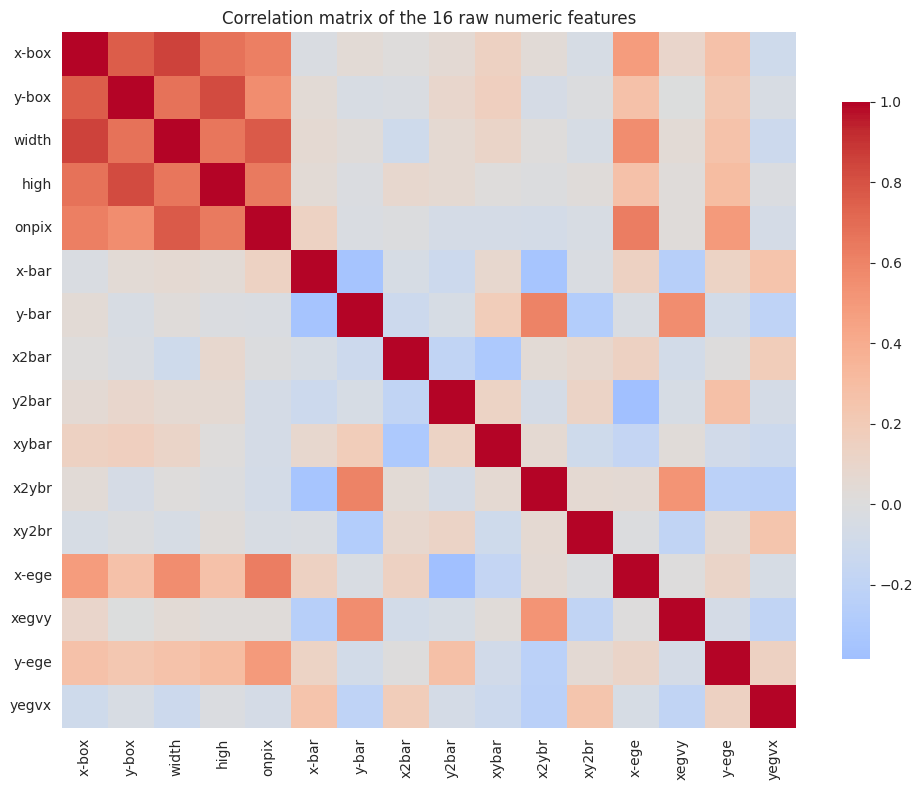

Feature pairs with |correlation| > 0.6:
  x-box    <-> width     r = 0.852
  y-box    <-> high      r = 0.823
  width    <-> onpix     r = 0.766
  x-box    <-> y-box     r = 0.758
  x-box    <-> high      r = 0.673
  y-box    <-> width     r = 0.672
  width    <-> high      r = 0.66
  high     <-> onpix     r = 0.644
  onpix    <-> x-ege     r = 0.628
  x-box    <-> onpix     r = 0.619
  y-bar    <-> x2ybr     r = 0.6


In [2]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Correlation matrix of the 16 raw numeric features')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/muhunthan_correlation_heatmap.png', dpi=110)
plt.show()

# Flag highly correlated pairs (|r| > 0.6, excluding the diagonal)
high_corr_pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        r = corr.iloc[i, j]
        if abs(r) > 0.6:
            high_corr_pairs.append((corr.columns[i], corr.columns[j], round(r, 3)))

print("Feature pairs with |correlation| > 0.6:")
for pair in sorted(high_corr_pairs, key=lambda t: -abs(t[2])):
    print(f"  {pair[0]:8s} <-> {pair[1]:8s}  r = {pair[2]}")


**Interpretation:** Most features are only weakly correlated with each other, which is
encouraging — it suggests the dataset's creators already engineered a fairly non-redundant set of
statistical descriptors. A small number of pairs show moderate-to-strong correlation (for example,
pairs involving the `x2ybr`/`xy2br` cross-moment features), which are natural candidates to review if
we later need to shrink the feature set further for a simpler model.


## 4. Filter Method: ANOVA F-test (SelectKBest)


In [3]:
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

f_scores = pd.Series(selector.scores_, index=feature_cols).sort_values(ascending=False)
print("Features ranked by ANOVA F-score (higher = more discriminative):")
print(f_scores.round(1))

selected_by_filter = list(f_scores.head(10).index)
print("\nTop 10 features selected by the filter method:")
print(selected_by_filter)


Features ranked by ANOVA F-score (higher = more discriminative):
x2ybr    1241.4
y-bar    1172.2
x-ege    1080.2
xegvy     917.1
xy2br     915.6
y2bar     752.4
y-ege     640.7
x2bar     407.2
xybar     349.5
x-bar     349.1
yegvx     283.5
width     129.6
onpix     110.9
x-box      76.0
high       10.3
y-box       3.3
dtype: float64

Top 10 features selected by the filter method:
['x2ybr', 'y-bar', 'x-ege', 'xegvy', 'xy2br', 'y2bar', 'y-ege', 'x2bar', 'xybar', 'x-bar']


## 5. Embedded Method: Random Forest Feature Importance


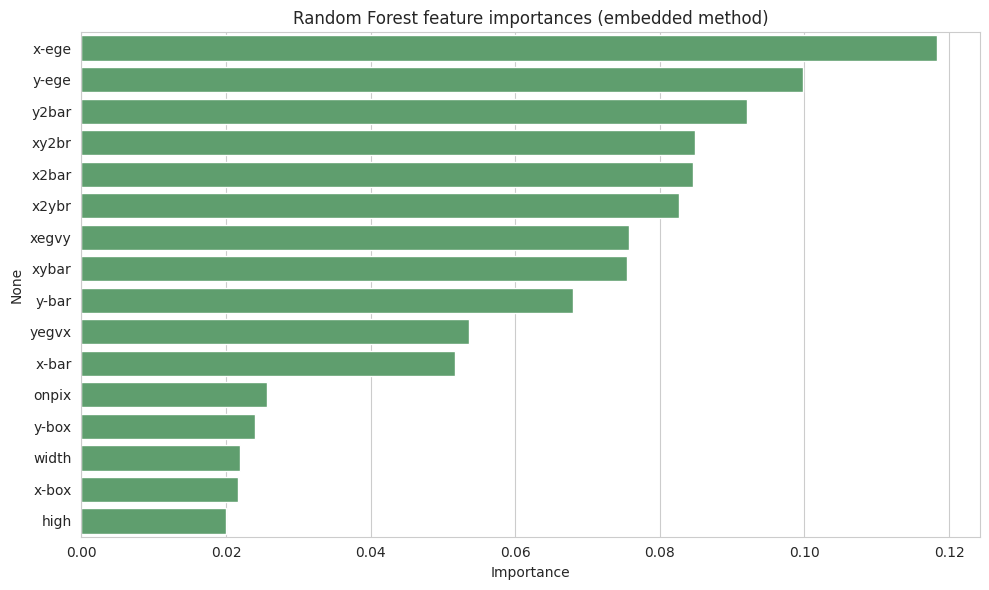

x-ege    0.1184
y-ege    0.0998
y2bar    0.0921
xy2br    0.0848
x2bar    0.0846
x2ybr    0.0827
xegvy    0.0758
xybar    0.0754
y-bar    0.0680
yegvx    0.0536
x-bar    0.0516
onpix    0.0257
y-box    0.0240
width    0.0219
x-box    0.0216
high     0.0200
dtype: float64


In [4]:
rf = RandomForestClassifier(n_estimators=150, max_depth=None, random_state=42, n_jobs=-1)
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, color='#55A868', ax=ax)
ax.set_title('Random Forest feature importances (embedded method)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/muhunthan_rf_feature_importance.png', dpi=110)
plt.show()

print(importances.round(4))


**Interpretation:** `x-ege`, `y-ege`, `xy2br`, and `x2ybr` come out as the most important
features under the Random Forest's internal splitting criteria — broadly consistent with the ANOVA
ranking above, giving us two independent methods that agree on which features carry the most signal.
Positional features like `x-box`/`y-box` rank comparatively lower on both methods, suggesting the
character's *position* in the scanned frame is less informative than its *shape/edge* statistics —
which matches domain intuition for an OCR task.


## 6. Dimension Reduction: PCA


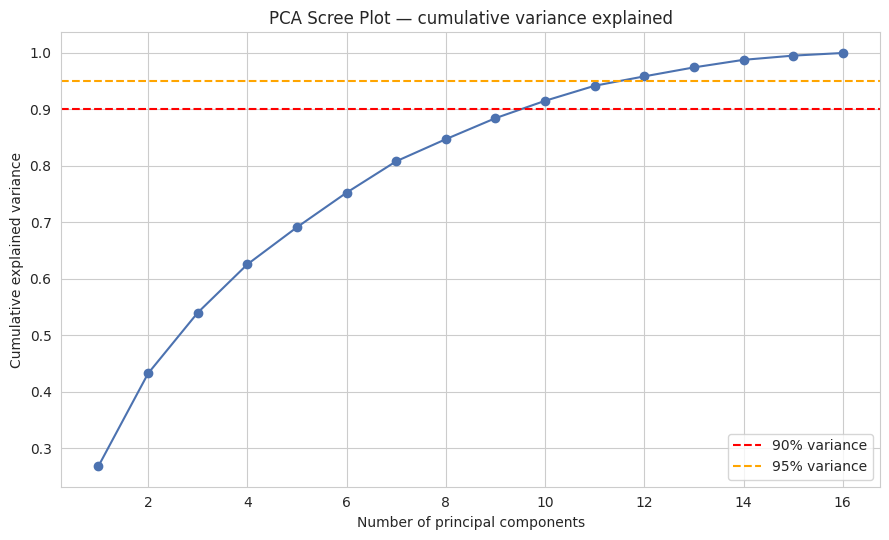

Components needed for >=90% variance: 10 (out of 16 original features)
Components needed for >=95% variance: 12 (out of 16 original features)


In [5]:
X_scaled = StandardScaler().fit_transform(X)

pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(range(1, len(cum_var) + 1), cum_var, marker='o', color='#4C72B0')
ax.axhline(0.90, color='red', linestyle='--', label='90% variance')
ax.axhline(0.95, color='orange', linestyle='--', label='95% variance')
ax.set_xlabel('Number of principal components')
ax.set_ylabel('Cumulative explained variance')
ax.set_title('PCA Scree Plot — cumulative variance explained')
ax.legend()
plt.tight_layout()
plt.savefig('../results/eda_visualizations/muhunthan_pca_scree_plot.png', dpi=110)
plt.show()

n_90 = int(np.argmax(cum_var >= 0.90) + 1)
n_95 = int(np.argmax(cum_var >= 0.95) + 1)
print(f"Components needed for >=90% variance: {n_90} (out of {X.shape[1]} original features)")
print(f"Components needed for >=95% variance: {n_95} (out of {X.shape[1]} original features)")


**Interpretation:** The scree plot shows variance is spread fairly evenly across many
components rather than being concentrated in the first two or three — the dataset does not have a
single dominant axis of variation, likely because 26 visually distinct letter shapes each require
their own combination of features to characterise. Still, a meaningful reduction is possible: the
`n_90` and `n_95` values printed above show how many components are needed to reach 90% and 95% of
the total variance respectively — noticeably fewer than the original 16 features, which is useful if
training time becomes a concern with more complex models in Progress Review II.


## 7. EDA Visualization: 2D PCA Projection


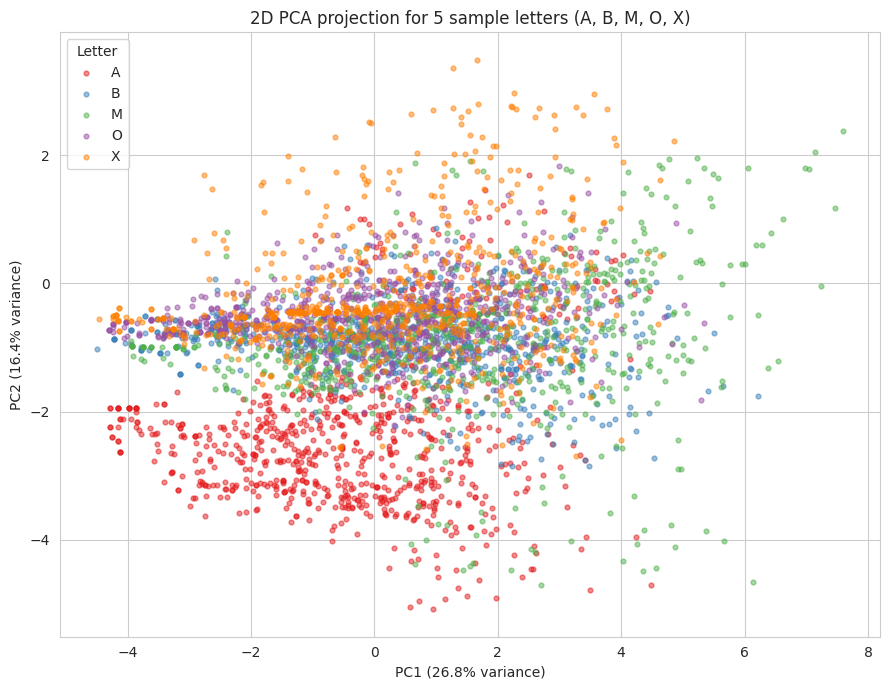

In [6]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

subset_letters = ['A', 'B', 'M', 'O', 'X']
mask = df['lettr'].isin(subset_letters)

fig, ax = plt.subplots(figsize=(9, 7))
palette = sns.color_palette('Set1', n_colors=len(subset_letters))
for letter, color in zip(subset_letters, palette):
    letter_mask = mask & (df['lettr'] == letter)
    ax.scatter(X_pca_2d[letter_mask, 0], X_pca_2d[letter_mask, 1],
               label=letter, alpha=0.5, s=12, color=color)
ax.set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('2D PCA projection for 5 sample letters (A, B, M, O, X)')
ax.legend(title='Letter')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/muhunthan_pca_2d_scatter.png', dpi=110)
plt.show()


**Interpretation:** Even with only the first two principal components (a small fraction of
total variance), the five sample letters form partially separated clusters — 'M' and 'O' in
particular occupy visibly different regions from 'A' and 'X'. This shows the class-separating
information is not confined to any single raw feature, but is distributed across the dataset in a
way that PCA can partially recover in just two dimensions — full separation across all 26 classes
would require more components, consistent with the scree plot above.


## 8. Conclusion

- **Correlation analysis** found only a small number of moderately-correlated feature pairs — this
  dataset is not heavily redundant.
- **Filter (ANOVA F-test)** and **embedded (Random Forest importance)** methods largely agree on
  which features are most discriminative: edge-count and cross-moment features rank highest;
  positional features rank lowest.
- **PCA** shows variance is spread across many components rather than concentrated in a few, but a
  meaningful reduction to ~90% variance is still achievable at less than the full 16 dimensions.
- **Recommendation for the group pipeline:** retain all 16 original features plus Danishiyan G.J.'s 5
  engineered features (21 total), apply PCA after scaling, and keep enough components to reach 95%
  cumulative explained variance for the modelling stage in Progress Review II.
